<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/Week_12_Student_Performance_TTest_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12 Participation Activity: Statistics & Hypothesis Testing

**Student:** Kai Xing




## 1. Import packages and load the data

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import os
import subprocess
from pathlib import Path

# GitHub repository
owner = "kaixing189"
repository = "MSSP607"

repo_url = f"https://github.com/{owner}/{repository}.git"
repo_path = Path("/content") / repository

# Clone the repository
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

# Move into the repository
os.chdir(repo_path)

print("Current directory:", os.getcwd())

# Read the Student Performance dataset
df = pd.read_csv("data/Student Performance Data (2).csv")

print("Dataset shape:", df.shape)
df.head()

Repository already exists. Using the existing copy.
Current directory: /content/MSSP607
Dataset shape: (1000, 10)


,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


In [12]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())


Columns:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'math score', 'reading score', 'writing score', 'total score', 'test preparation course', 'admission prospect']

Missing values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
math score                     0
reading score                  0
writing score                  0
total score                    0
test preparation course        0
admission prospect             0
dtype: int64


## 2. Create the comparison groups

The assignment asks whether there is a statistical difference between **males who took the preparation exam/course and others**.

I define:

- **Male + completed preparation course** = male students whose `test preparation course` is `completed`
- **Others** = all remaining students

The outcome for the main t-test is `total score`.


In [13]:
df["male_completed_prep"] = (
    (df["gender"] == "male") &
    (df["test preparation course"] == "completed")
).astype(int)

group1 = df.loc[df["male_completed_prep"] == 1, "total score"]
group2 = df.loc[df["male_completed_prep"] == 0, "total score"]

summary_main = pd.DataFrame({
    "Group": ["Male + completed prep", "Others"],
    "N": [len(group1), len(group2)],
    "Mean total score": [group1.mean(), group2.mean()],
    "SD": [group1.std(ddof=1), group2.std(ddof=1)]
})

display(summary_main.round(2))


,Group,N,Mean total score,SD
0,Male + completed prep,174,212.34,39.60
1,Others,826,201.41,43.19


## 3. Main independent-samples t-test

I use **Welch's independent-samples t-test** because it does not require the two groups to have exactly equal variances.

- **H₀:** The mean total score is the same for males who completed the preparation course and other students.
- **H₁:** The mean total score is different between the two groups.


In [14]:
t_main = stats.ttest_ind(
    group1,
    group2,
    equal_var=False
)

mean_difference = group1.mean() - group2.mean()

# 95% confidence interval for the difference in means
se_diff = np.sqrt(
    group1.var(ddof=1) / len(group1) +
    group2.var(ddof=1) / len(group2)
)

critical_t = stats.t.ppf(
    0.975,
    t_main.df
)

ci_low = mean_difference - critical_t * se_diff
ci_high = mean_difference + critical_t * se_diff

print(f"Mean difference: {mean_difference:.2f}")
print(f"Welch t-statistic: {t_main.statistic:.3f}")
print(f"Degrees of freedom: {t_main.df:.2f}")
print(f"p-value: {t_main.pvalue:.6f}")
print(f"95% CI for mean difference: [{ci_low:.2f}, {ci_high:.2f}]")


Mean difference: 10.94
Welch t-statistic: 3.257
Degrees of freedom: 267.07
p-value: 0.001270
95% CI for mean difference: [4.33, 17.55]


### Answer to Question 2

Yes. There is a statistically significant difference in total scores between males who completed the test preparation course and all other students.

Males who completed the preparation course had a mean total score of **212.34** (SD = **39.60**, n = **174**), compared with **201.41** (SD = **43.19**, n = **826**) for the other students. Welch's independent-samples t-test showed that this difference was statistically significant, **t(267.07) = 3.26, p = .0013**. The estimated mean difference was **10.94 points**, with a 95% confidence interval from approximately **4.33 to 17.55 points**.

Therefore, I reject the null hypothesis and conclude that males who completed the preparation course had higher total scores on average than the other students in this dataset. This result is an association and does not show that completing the preparation course caused the difference.


### Plot of the main comparison

/tmp/ipykernel_1200/1376966686.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


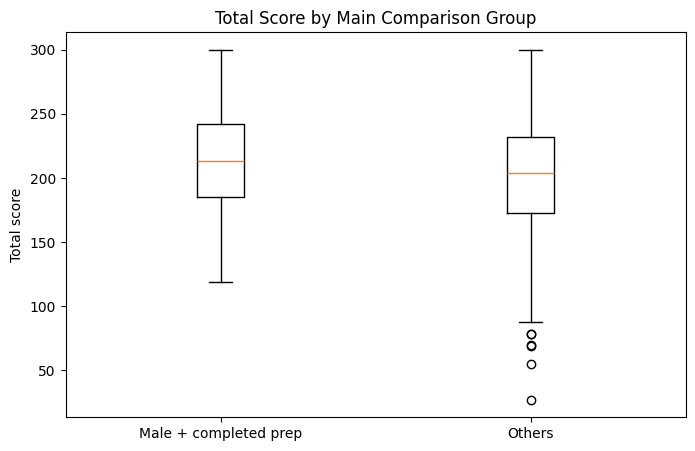

In [15]:
plot_data = [
    group1,
    group2
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    plot_data,
    labels=["Male + completed prep", "Others"]
)
plt.ylabel("Total score")
plt.title("Total Score by Main Comparison Group")
plt.show()


## 4. Which score appears to drive the difference?

Because `total score` is the sum of math, reading, and writing, I also compare the three component scores. These are exploratory comparisons.


In [16]:
score_results = []

for score in ["math score", "reading score", "writing score", "total score"]:
    male_prep = df.loc[df["male_completed_prep"] == 1, score]
    others = df.loc[df["male_completed_prep"] == 0, score]

    test = stats.ttest_ind(
        male_prep,
        others,
        equal_var=False
    )

    score_results.append({
        "Score": score,
        "Male + prep mean": male_prep.mean(),
        "Others mean": others.mean(),
        "Difference": male_prep.mean() - others.mean(),
        "t": test.statistic,
        "p-value": test.pvalue
    })

score_results = pd.DataFrame(score_results)
display(score_results.round(3))


,Score,Male + prep mean,Others mean,Difference,t,p-value
0,math score,72.339,64.772,7.567,6.314,0.000
1,reading score,70.213,68.949,1.263,1.092,0.276
2,writing score,69.793,67.688,2.105,1.872,0.062
3,total score,212.345,201.409,10.936,3.257,0.001


### Interpretation

The largest difference is in **math score**. Males who completed the preparation course averaged about **72.34** in math, compared with **64.77** among other students, a difference of about **7.57 points** (**p < .001**).

The reading-score difference is small and not statistically significant (**p ≈ .276**), while the writing-score difference is also not conventionally significant at the .05 level (**p ≈ .062**). This suggests that the statistically significant difference in total score is driven mainly by the math-score difference.


## 5. Other differences of interest

Two additional comparisons are useful:

1. Students who completed the preparation course versus students who did not complete it, regardless of gender.
2. Students receiving standard lunch versus students receiving free/reduced lunch.

These comparisons are exploratory and should not be interpreted as causal effects.


In [17]:
def welch_test_summary(data, group_col, group_a, group_b, outcome="total score"):
    a = data.loc[data[group_col] == group_a, outcome]
    b = data.loc[data[group_col] == group_b, outcome]

    test = stats.ttest_ind(a, b, equal_var=False)

    return {
        "Comparison": f"{group_a} vs {group_b}",
        "N group 1": len(a),
        "Mean group 1": a.mean(),
        "N group 2": len(b),
        "Mean group 2": b.mean(),
        "Difference": a.mean() - b.mean(),
        "t": test.statistic,
        "p-value": test.pvalue
    }

extra_results = pd.DataFrame([
    welch_test_summary(
        df,
        "test preparation course",
        "completed",
        "none"
    ),
    welch_test_summary(
        df,
        "lunch",
        "standard",
        "free/reduced"
    ),
    welch_test_summary(
        df,
        "gender",
        "female",
        "male"
    )
])

display(extra_results.round(3))


,Comparison,N group 1,Mean group 1,N group 2,Mean group 2,Difference,t,p-value
0,completed vs none,358,218.008,642,195.117,22.892,8.595,0.0
1,standard vs free/reduced,645,212.512,355,186.597,25.914,9.323,0.0
2,female vs male,518,208.708,482,197.512,11.196,4.179,0.0


### Answer to Question 3

There are several other differences of interest in the dataset.

First, students who completed the test preparation course had a substantially higher mean total score than students who did not complete it (**218.01 vs. 195.12**). The mean difference was about **22.89 points**, and the Welch t-test was statistically significant (**t ≈ 8.59, p < .001**).

Second, students receiving a standard lunch had a higher mean total score than students receiving free/reduced lunch (**212.51 vs. 186.60**). This difference of about **25.91 points** was also statistically significant (**t ≈ 9.32, p < .001**).

There was also a smaller gender difference in total score: female students averaged approximately **208.71**, compared with **197.51** for male students (**p < .001**).

These are exploratory associations. Other variables, such as family background or prior academic performance, could contribute to the observed group differences, so the t-tests should not be interpreted as evidence of causation.


### Plot of test-preparation-course difference

/tmp/ipykernel_1200/519295766.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


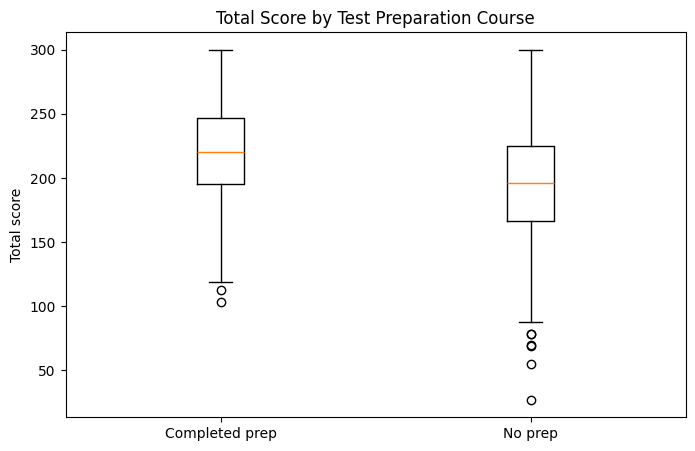

In [18]:
completed = df.loc[
    df["test preparation course"] == "completed",
    "total score"
]

none = df.loc[
    df["test preparation course"] == "none",
    "total score"
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    [completed, none],
    labels=["Completed prep", "No prep"]
)
plt.ylabel("Total score")
plt.title("Total Score by Test Preparation Course")
plt.show()


## Final Summary

The main analysis found that males who completed the test preparation course had significantly higher total scores than other students. The difference was about 10.94 points and was statistically significant at the .05 level.

Additional analysis suggests that the main result is driven mostly by a difference in math scores. The dataset also shows strong differences associated with completing the preparation course overall and with lunch status. These results identify patterns in the sample, but they do not establish causal relationships.
